# 1.2 Exploración de P2: riesgo aproximado por capacidad

P2: ¿una estación estará en riesgo de quedarse sin bicicletas o sin anclajes en la siguiente hora? MiBici no publica inventario, así que el riesgo se **aproxima** con los viajes y la capacidad publicada. Prueba no se usa aquí.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

from mibici_equipo39 import config as C
from mibici_equipo39.features import FEATURE_COLUMNS, LAG_FEATURES, load_p2_targets, load_tables, proxy_labels

metadata, X, _ = load_tables()
df = pd.concat([metadata, X, load_p2_targets()], axis=1)
df = df.loc[df["capacity"].notna()].reset_index(drop=True)
train = df["split"].eq("train").to_numpy()
val = df["split"].eq("validation").to_numpy()
print(df["station_id"].nunique(), "estaciones con capacidad válida,", len(df), "filas estación-hora")

469 estaciones con capacidad válida, 4018392 filas estación-hora


## Cómo se construye la etiqueta

In [2]:
example = pd.DataFrame({"capacidad": [20.0, 40.0, 20.0], "flujo_min": [-8, -8, 0], "flujo_max": [0, 0, 8]})
example["y_bikes"], example["y_docks"] = proxy_labels(example["flujo_min"], example["flujo_max"], example["capacidad"])
example

,capacidad,flujo_min,flujo_max,y_bikes,y_docks
0,20.0,-8,0,1,0
1,40.0,-8,0,0,0
2,20.0,0,8,0,1


> **Trayectoria y no flujo final.** Cada hora empieza con 50% de la capacidad y se suman llegadas y restan salidas evento por evento. Hay riesgo de bicicletas si en algún momento quedan 10% o menos, y de anclajes si se llega a 90%. Con el mínimo y el máximo se detecta una estación que se vacía a media hora aunque se recupere al final. Las mismas 8 salidas son riesgo con capacidad 20 y no con 40.

## Qué tan raras son

In [3]:
print("horas con los dos riesgos:", int((df["y_bikes"].eq(1) & df["y_docks"].eq(1)).sum()))
df.groupby("split")[["y_bikes", "y_docks"]].agg(["mean", "sum"]).round(4)

horas con los dos riesgos: 19


y_bikes        y_docks       
              mean    sum    mean    sum
split                                   
test        0.0038   2288  0.0050   3012
train       0.0039  11126  0.0051  14356
validation  0.0040   2324  0.0051   2971

> **Métricas.** Menos de 1% de las horas son positivas: un modelo que nunca alerta tendría 99% de exactitud y no serviría. Se usan recall, precisión, F1 y AP. La prevalencia es casi igual en los tres conjuntos porque la partición reparte días de todos los meses. Las horas con los dos riesgos son casi nulas, así que se tratan como alerta de revisión.

## Dónde y cuándo

,y_bikes,y_docks
estaciones_con_positivos,285.000,281.000
share_10pct_estaciones,0.592,0.664


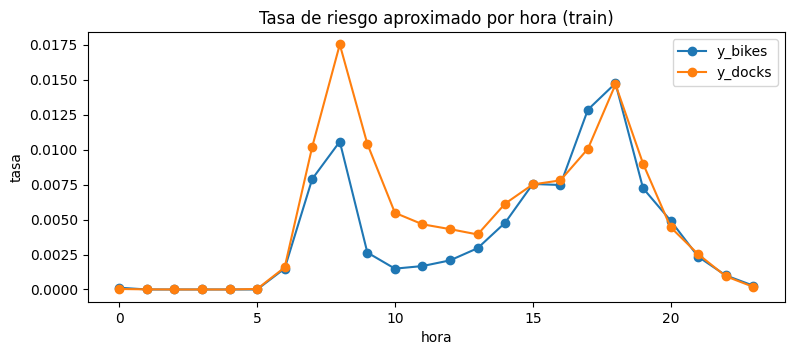

In [4]:
tr = df.loc[train]
concentration = {}
for target in ["y_bikes", "y_docks"]:
    per_station = tr.groupby("station_id", observed=True)[target].sum().sort_values(ascending=False)
    top = round(len(per_station) * 0.10)
    concentration[target] = {"estaciones_con_positivos": int((per_station > 0).sum()), "share_10pct_estaciones": round(per_station.head(top).sum() / per_station.sum(), 3)}
ax = tr.groupby("hour_of_day")[["y_bikes", "y_docks"]].mean().plot(figsize=(9, 3.5), marker="o", title="Tasa de riesgo aproximado por hora (train)")
ax.set(xlabel="hora", ylabel="tasa")
plt.savefig(C.FIGURES / "p2_tasa_por_hora.png", dpi=120, bbox_inches="tight")
pd.DataFrame(concentration)

In [5]:
tr.groupby(pd.cut(tr["capacity"], [0, 14, 15, 19, 40]), observed=True)[["y_bikes", "y_docks"]].mean().round(4)

,y_bikes,y_docks
capacity,,
"(0, 14]",0.0076,0.0069
"(14, 15]",0.0047,0.0070
"(15, 19]",0.0019,0.0022
"(19, 40]",0.0040,0.0053


> **El modelo tiene que saber de qué estación se trata.** Un 10% de las estaciones junta más de la mitad de los positivos y el riesgo tiene picos en horas de traslado. Las estaciones más chicas (14 anclajes o menos) tienen la tasa más alta, aunque la relación no es lineal. La capacidad no entra como variable: es una foto de septiembre de 2026 y ya está dentro de la etiqueta.

## Sensibilidad a la ocupación inicial

In [6]:
rows = {}
for occupancy in [0.25, 0.50, 0.75]:
    bikes, docks = proxy_labels(df["flow_min"], df["flow_max"], df["capacity"], occupancy=occupancy)
    rows[occupancy] = {"prevalencia_bikes": bikes.mean(), "prevalencia_docks": docks.mean()}
pd.DataFrame(rows).T.round(4)

,prevalencia_bikes,prevalencia_docks
0.25,0.0552,0.0006
0.50,0.0039,0.0051
0.75,0.0004,0.0615


> **Es una aproximación.** Con 25% de ocupación inicial el riesgo de bicicletas pasa de 0.4% a más de 5%; con 75% pasa lo mismo con anclajes. Por eso las salidas se llaman `riesgo_proxy_bicicletas` y `riesgo_proxy_anclajes` y los puntajes sirven para ordenar estaciones, no como probabilidad real de desabasto.

## Comparación de modelos

Para cada riesgo se entrena en train y se elige el umbral en validación: el de mayor precisión entre los que detectan al menos 80% de los riesgos.

In [7]:
def threshold(y, s):
    p, r, t = precision_recall_curve(y, s)
    table = pd.DataFrame({"t": t, "p": p[:-1], "r": r[:-1]})
    ok = table[table["r"] >= C.P2_MIN_RECALL]
    return ok.loc[ok["p"] == ok["p"].max(), "t"].max()

def seasonal_rate(target):
    s = pd.Series(np.nan, index=df.index)
    for key in [["station_id", "is_weekend", "hour_of_day"], ["station_id"]]:
        s = s.fillna(df[key].join(tr.groupby(key, observed=True)[target].mean().rename("r"), on=key)["r"])
    return s.fillna(tr[target].mean()).to_numpy()

def logistic(target):
    cat, num = ["station_id", "hour_of_day", "day_of_week", "month"], LAG_FEATURES + ["is_weekend"]
    m = make_pipeline(ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), cat), ("n", StandardScaler(), num)]),
                      LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000, random_state=C.SEED))
    return m.fit(tr[cat + num], tr[target]).predict_proba(df[cat + num])[:, 1]

def hgb(target):
    m = HistGradientBoostingClassifier(**C.P2_HGB_PARAMS).fit(tr[FEATURE_COLUMNS], tr[target])
    return m.predict_proba(df[FEATURE_COLUMNS])[:, 1]

def hgb_target_encoding(target):
    keys = lambda f: pd.DataFrame({"te_station": f["station_id"].astype(str),
                                   "te_station_hour": f["station_id"].astype(str) + "|" + f["is_weekend"].astype(str) + "|" + f["hour_of_day"].astype(str)})
    enc = TargetEncoder(target_type="binary", cv=5, shuffle=True, random_state=C.SEED)
    a = pd.DataFrame(enc.fit_transform(keys(tr), tr[target]), columns=["te_station", "te_station_hour"], index=tr.index)
    b = pd.DataFrame(enc.transform(keys(df)), columns=["te_station", "te_station_hour"], index=df.index)
    m = HistGradientBoostingClassifier(**C.P2_HGB_PARAMS).fit(pd.concat([tr[FEATURE_COLUMNS], a], axis=1), tr[target])
    return m.predict_proba(pd.concat([df[FEATURE_COLUMNS], b], axis=1))[:, 1]

models = {"baseline_frecuencia": seasonal_rate, "logistica": logistic, "hgb": hgb, "hgb_target_encoding": hgb_target_encoding}
n_stations = df["station_id"].nunique()
scores, results = {}, {}
for name, fn in models.items():
    row = {}
    for risk, target in [("bikes", "y_bikes"), ("docks", "y_docks")]:
        s = fn(target)
        scores[(name, risk)] = s
        y, sv = df[target].to_numpy()[val], s[val]
        alert = sv >= threshold(y, sv)
        precision, recall = y[alert].mean(), alert[y == 1].mean()
        row.update({f"precision_{risk}": precision, f"f1_{risk}": 2 * precision * recall / (precision + recall),
                    f"ap_{risk}": average_precision_score(y, sv), f"alertas_por_hora_{risk}": alert.mean() * n_stations})
    row["macro_f1"] = (row["f1_bikes"] + row["f1_docks"]) / 2
    results[name] = row
pd.DataFrame(results).T.round(4)

,precision_bikes,f1_bikes,ap_bikes,alertas_por_hora_bikes,precision_docks,f1_docks,ap_docks,alertas_por_hora_docks,macro_f1
baseline_frecuencia,0.0482,0.0910,0.1959,31.6571,0.0850,0.1540,0.3111,23.0128,0.1225
logistica,0.0510,0.0959,0.1489,29.2284,0.0785,0.1430,0.2449,24.2548,0.1194
hgb,0.0334,0.0641,0.0625,44.6050,0.0541,0.1013,0.2003,35.2268,0.0827
hgb_target_encoding,0.0589,0.1097,0.1472,25.3005,0.0909,0.1633,0.2713,20.9479,0.1365


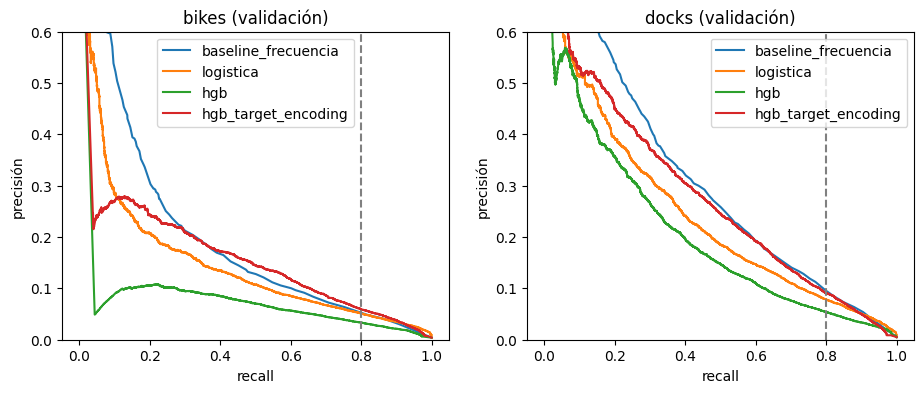

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (risk, target) in zip(axes, [("bikes", "y_bikes"), ("docks", "y_docks")]):
    y = df[target].to_numpy()[val]
    for name in models:
        p, r, _ = precision_recall_curve(y, scores[(name, risk)][val])
        ax.plot(r, p, label=name)
    ax.axvline(C.P2_MIN_RECALL, color="grey", linestyle="--")
    ax.set(title=f"{risk} (validación)", xlabel="recall", ylabel="precisión", ylim=(0, 0.6))
    ax.legend()
plt.savefig(C.FIGURES / "p2_comparacion_modelos.png", dpi=120, bbox_inches="tight")

> **Elección: HistGradientBoosting con target encoding.**
> - **Baseline:** frecuencia histórica por estación, fin de semana y hora. Es lo que haría el equipo de rebalanceo con su historial y resultó difícil de superar.
> - **Logística** (la propuesta del instructivo): no supera al baseline en macro F1 y tiene menor AP.
> - **HGB sin target encoding:** es el peor. Igual que en P1, sin saber la estación no ubica dónde está el riesgo.
> - **HGB con target encoding:** con el mismo 80% de recall tiene la mayor precisión en los dos riesgos y menos alertas por hora. Junta la tasa histórica de la estación con la presión de las últimas horas. El encoding se ajusta con validación cruzada dentro de train para que ninguna fila vea su propia etiqueta.
> - **Lo que no gana:** el baseline tiene mejor AP. Ordena mejor las pocas estaciones con riesgo evidente, pero pierde en el punto de operación, que es el que importa para no dejar estaciones sin visitar.

## Decisión

| | Elección |
|---|---|
| Baseline | Frecuencia de train por estación, fin de semana y hora |
| Candidato | HistGradientBoostingClassifier + TargetEncoder, un modelo por riesgo, semilla 39 |
| Variables | Calendario y rezagos de `features.py` más tasa histórica por estación y estación-hora |
| Umbral | Mayor precisión con recall >= 0.80 en validación |
| Regla | Se queda el candidato si mejora `val_macro_f1`; prueba se mide una vez en MLflow |

Siguiente paso: `2.2-dm-p2-refactorizacion`.